In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import shapiro
from wordcloud import WordCloud, STOPWORDS


In [2]:
df = pd.read_csv("train_data.csv")

C:\Users\pouria\AppData\Local\Temp\ipykernel_9316\3930997622.py:1: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("train_data.csv")


1.)
با توجه به اینکه مجموعه داده نامتوازن است و در  پروژه ما نیاز داریم که احساسات رو تحلیل کنیم و به درستی تشخیص بدیم این رو  چون داده نامتوازن است ممکن است که 
مدل به سمتی که تغداد بیشتری دارد متمایل شود 
برای متوازن کردن هم در کل سه روش موحود است اولی این است که تعداد داده هایی که زیاد است را به حداقل ها برسانیم که باعث میشود که بعضی داده ها که بعضا مهم هم هستند 
حذف بشوند راه حل  دوم این است که برای کلاس‌هایی که تعداد نمونه‌های کمتری دارند داده های مصنوعی درست گکنیم و تعداد اینهارو زیاد کنیم ککه این کار هم ممکن است باعت اورفیت 
بشود برای همین از راه حل سوم استفاده میکنیم که وزن دادن است میتونی داخل مدل از Class Weight استفاده کنیم و در نهایت اثر نامتوازن بودن داده را کم کنیم 
واگر این راه به جواب خوبی به ما نداد از روش های دیگه استغاده کنیم

e:\anacoda\Lib\site-packages\scipy\stats\_axis_nan_policy.py:531: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 838944.
  res = hypotest_fun_out(*samples, **kwds)


Statistic: 0.7269114267971863
P-value: 3.503909674572388e-186
The data does not follow a normal distribution.


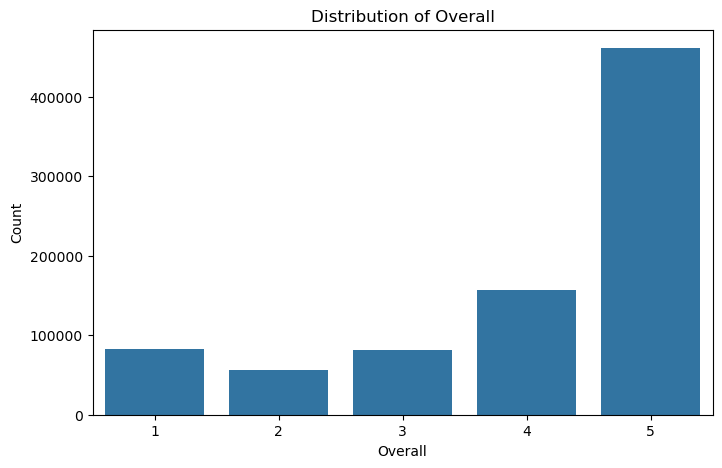

In [3]:
stat, p_value = shapiro(df['overall'].dropna())

print("Statistic:", stat)
print("P-value:", p_value)

if p_value > 0.05:
    print("The data follows a normal distribution.")
else:
    print("The data does not follow a normal distribution.")
    
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='overall', order=sorted(df['overall'].dropna().unique()))

plt.title('Distribution of Overall')
plt.xlabel('Overall')
plt.ylabel('Count')
plt.show()

2.)
بین دو دسته مثبت و منفی کلماتی هستند که مشترک اند ولی این به این معنی نیست که متن کلی آنها یکسان باشند  برای مثال کلمه هایی مثل محصول - کار کردن - استفاده - کیفیت بودند
هردو از آنها استفاده کرده بودند اما در کل میتوانستند نظر های مختلفی داشته باشند برای مثال یک کاربر میتواند نوشته باشد من از کیفیت این محصول و کارکردش راضی بودم 
و برعکس کاربر دیگری نوشته باشد من از این محصول و کارکردش راضی نبودم
و بعضی کلمات بودند مانند گوشی صرفا به موضوع یا نوع محصول اشاره میکنند  و میتواند در ادامه این را بگوید که راضی بودند و یا اینکه اصلا راضی نبودند
در نتیحه پر تکرار بودن کلمات به تنهایی نمیتواند نشانه مثبت یا منفی بودن نظر را نشان دهد

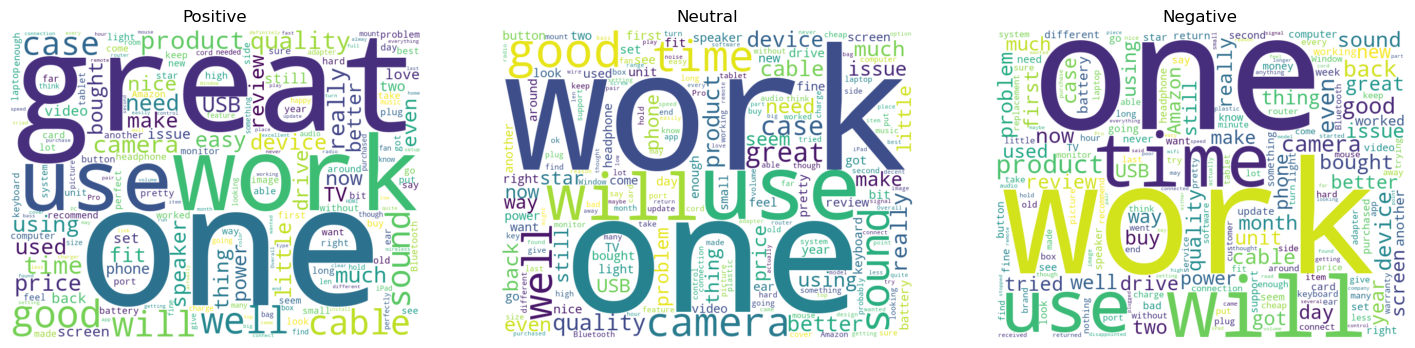

In [4]:
df['sentiment'] = df['overall'].map({
    1: 'negative',
    2: 'negative',
    3: 'neutral',
    4: 'positive',
    5: 'positive'
})

positive_df = df[df['sentiment'] == 'positive']
neutral_df = df[df['sentiment'] == 'neutral']
negative_df = df[df['sentiment'] == 'negative']

positive_text = ' '.join(positive_df['reviewText'].dropna())
neutral_text = ' '.join(neutral_df['reviewText'].dropna())
negative_text = ' '.join(negative_df['reviewText'].dropna())

texts = [positive_text, neutral_text, negative_text]
titles = ['Positive', 'Neutral', 'Negative']

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, text, title in zip(axes, texts, titles):
    wordcloud = WordCloud(
        width=800,
        height=600,
        background_color='white',
        stopwords=STOPWORDS,
        collocations=False
    ).generate(text)

    ax.imshow(wordcloud, interpolation='bilinear')
    ax.set_title(title)
    ax.axis('off')

3.)

In [5]:
df['vote'] = pd.to_numeric(df['vote'], errors='coerce').fillna(0)

top10 = (
    df.groupby('reviewerID')
    .agg(
        name=('reviewerName', 'first'),
        total_vote=('vote', 'sum')
    )
    .sort_values('total_vote', ascending=False)
    .head(10)
)

print(top10[['name', 'total_vote']])

                             name  total_vote
reviewerID                                   
A25GROL6KJV3QG       Benson Leung      4572.0
A2IK776FY6MEMG            Obi Wan      1608.0
A1A39899KH5QCI       Chris Winter      1352.0
AMYCUX8EWEUVV            Mayra S.      1342.0
A9K7V1MKJ9BOJ          VermontGuy      1337.0
A1UQUDT2Q0YENM            Michael      1230.0
A3R1WFO4KIUQXZ      PhotoGraphics      1209.0
A2Z9APP5B09MFY           Nicholas      1188.0
AOEAD7DPLZE53   NLee the Engineer      1103.0
AZPCDY9OQ605E             David H      1045.0


4.)برای طول نظرات باید محدودیت هایی قرار داد  چون نظر های طولانی میتوانند باعث افزایش حجم حافظه مورد نیاز و محاسبات شود 
برای این کار ما از iqr استفاده کردیم چون حد پایین را منفی بدست می آورد و تعداد کاراکتر ها نمی توانند منفی باشند حد پایین را صفر میگذاریم
 که یعنی از داده هایی که طول آنها کم است فیلتر نمیکنیم 
ولی داده هایی که طول آنها بیش از حد زیاد است را فیلتر کردیم
برای این قیمت ما میتوانیم که نظراتی که تغداد کاراکتر های زیادی دارند را محدود کنیم یعنی از آخر یا اول یا هردو مقداری از این کاراکتر هارا فیلتر و محدود کنیم 
این کار باعث میشود که هم اندازه کاراکتر های ما از حدی بیشتر نشود هم همه نظراتی که تغداد کاراکتر زیادی دارند حذف نشوند و بشود تا حد امکان همه نظرات را دید

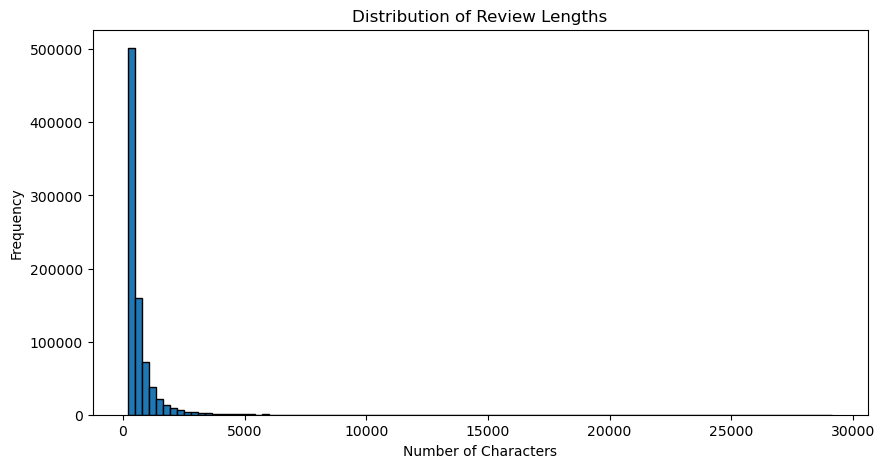

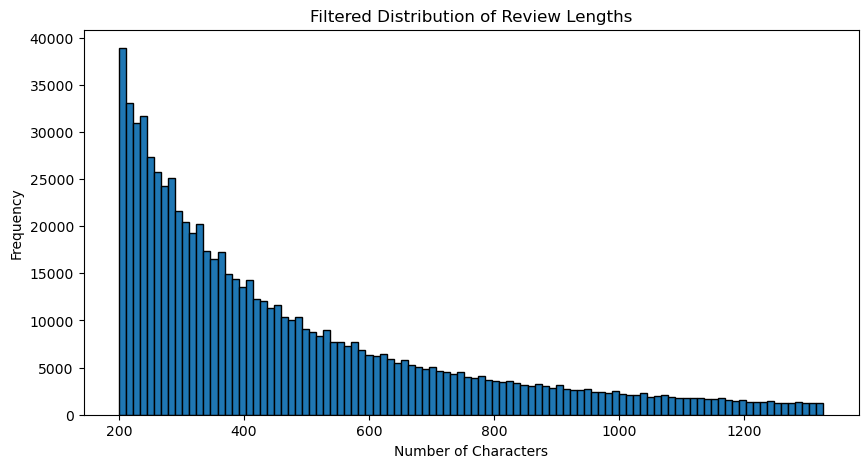

Lower limit: -353.0
Upper limit: 1327.0


In [6]:
df['review_length'] = df['reviewText'].astype('string').str.len()
lengths = df['review_length'].dropna()

plt.figure(figsize=(10, 5))
plt.hist(lengths, bins=100, edgecolor='black')

plt.title('Distribution of Review Lengths')
plt.xlabel('Number of Characters')
plt.ylabel('Frequency')
plt.show()

Q1 = lengths.quantile(0.25)
Q3 = lengths.quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR


filtered_lengths = lengths[
    lengths.between(max(0, lower), upper)
]

plt.figure(figsize=(10, 5))
plt.hist(filtered_lengths, bins=100, edgecolor='black')

plt.title('Filtered Distribution of Review Lengths')
plt.xlabel('Number of Characters')
plt.ylabel('Frequency')
plt.show()

print('Lower limit:', lower)
print('Upper limit:', upper)


5.)

In [7]:
brand_df = pd.read_csv('title_brand.csv')
df_brand = df.merge(
    brand_df[['asin', 'brand', 'title']].drop_duplicates('asin'),
    on='asin',
    how='left'
)

In [8]:
five_star_counts = (
    df[df['overall'] == 5]
    .groupby('asin')
    .size()
    .reset_index(name='five_star_count')
)
top10 = (
    df_brand[df_brand['overall'] == 5]
    .groupby(['asin', 'brand', 'title'])
    .size()
    .reset_index(name='five_star_count')
    .sort_values('five_star_count', ascending=False)
    .head(10)
)
print(top10[['brand', 'title', 'five_star_count']].to_string(index=False))

                 brand                                                                                                                                                                                                              title  five_star_count
  Cambridge Soundworks                                  OontZ Angle 3 Enhanced Stereo Edition IPX5 Splashproof Portable Bluetooth Speaker with Volume Booster AMP 10 Watts Power, Custom Bass Radiator, 100' Wireless Range Bluetooth 4.2             1163
               NETGEAR                                                                                                                                                                          NETGEAR N300 WiFi Range Extender (EX2700)              659
                  Roku                                                                                                                                        Roku Streaming Stick (3600R) - HD Streaming Player with Quad-Core Processor              

6.)

In [9]:
brand_stats = (
    df_brand.dropna(subset=['brand', 'overall'])
    .groupby('brand')
    .agg(
        review_count=('overall', 'count'),
        mean_overall=('overall', 'mean')
    )
    .reset_index()
)
top10_brands = brand_stats.nlargest(10, 'review_count')
result = top10_brands.sort_values('mean_overall' ,ascending=False)
print(
    result[['brand', 'mean_overall']]
    .round(2)
    .to_string(index=False)
)

       brand  mean_overall
       Anker          4.24
AmazonBasics          4.20
     Sabrent          4.03
     SanDisk          3.96
    Logitech          3.95
     Samsung          3.94
     TP-LINK          3.93
        Sony          3.92
        Asus          3.86
     NETGEAR          3.81
